# Integración de fotografías y base v2

**Manzana roja, banano y limón · Algoritmos y Programación III**

El equipo confirmó el 24/11/2026 que el limón sustituye a la naranja. La primera
carpeta de Drive es una fuente pública y la segunda contiene fotografías propias.
Los cuadernos 01–03 y la base v1 se conservan como antecedentes.

Objetivo: integrar originales, revisar etiquetas y máscaras y exportar una base
vigente para SVM y Random Forest. Las decisiones del asistente están atribuidas;
el equipo puede corregirlas en este cuaderno. Las fotos son vistas relacionadas,
no necesariamente frutos físicos diferentes.

## 1. Configuración y procedencia

Los originales ya están descargados. Este cuaderno no accede a la red ni vuelve a
descargar datos. Para reproducir la importación: `python -m src.data.importar_drive
--proyecto .`, seguido de `python -m src.data.integrar_fuentes --proyecto . --galerias`.
Se necesita `pillow-heif` para leer originales HEIC.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display,clear_output

candidatas=[Path.cwd(),*Path.cwd().parents,Path.cwd()/'proyecto_estado_frutas']
PROYECTO=next(p for p in candidatas if (p/'config/alcance_actual.json').is_file())
if str(PROYECTO) not in sys.path:sys.path.insert(0,str(PROYECTO))
from src.data.exportar_base_v2 import exportar,guardar_revision
from src.data.preparacion_imagenes import guardar_figura,guardar_tabla,guardar_bytes_si_cambio

ANOTACIONES=PROYECTO/'data/annotations/drive_20261124'
SALIDAS=PROYECTO/'experiments/results/base_revisada_v2'
SALIDAS.mkdir(parents=True,exist_ok=True)
config=json.loads((PROYECTO/'config/alcance_actual.json').read_text(encoding='utf-8'))
inventario=pd.read_csv(ANOTACIONES/'inventario_drive.csv',keep_default_na=False)
print('Alcance:',', '.join(config['frutas']))
print('Imágenes nuevas:',len(inventario),'| Legibles:',int(inventario.archivo_legible.sum()))
display(inventario.groupby(['fuente','fruta']).size().unstack(fill_value=0))

Alcance: manzana, banano, limon
Imágenes nuevas: 318 | Legibles: 318


fruta,banano,limon,manzana
fuente,,,
propia,12,14,25
publica,77,70,120


## 2. Integridad y etiquetas declaradas

Se conservaron 318 originales (267 públicos y 51 propios), sus rutas de Drive y
sus huellas SHA-256. Se comprobó lectura y orientación. Los duplicados se buscan
por archivo y por píxeles decodificados, además de compararse por bytes con Kaggle.
La ausencia de duplicados exactos no demuestra independencia entre vistas.

`calidad_declarada` conserva la carpeta de origen; `calidad_revisada` es una
decisión explícita tras inspección. El inventario completo y el lote detallado
se mantienen separados. Un cribado en galería no equivale a aprobar todas las fotos.

In [2]:
assert inventario.id_imagen.is_unique
assert inventario.codigo_revision.is_unique
assert inventario.descargado.all() and inventario.archivo_legible.all()
assert set(inventario.fruta)==set(config['frutas'])
print('Duplicados adicionales por bytes:',inventario.sha256.duplicated().sum())
print('Duplicados adicionales por píxeles:',inventario.sha_pixeles.duplicated().sum())
print('Coincidencias exactas con Kaggle:',inventario.duplicado_exacto_kaggle.sum())
propias=inventario.loc[inventario.fuente.eq('propia')]
display(pd.crosstab(propias.fruta,propias.calidad_declarada).reindex(
    index=config['frutas'],columns=config['calidades'],fill_value=0))

Duplicados adicionales por bytes: 0
Duplicados adicionales por píxeles: 0
Coincidencias exactas con Kaggle: 0


calidad_declarada,buena,intermedia,mala
fruta,,,
manzana,18,7,0
banano,0,0,12
limon,9,5,0


## 3. Revisión ampliada de calidad y máscara

Se completó la revisión de las 318 fotografías: 292 con un fruto aislable pasaron por
inspección de contorno y detalle; 270 se aceptaron y 22 se rechazaron por máscara o
encuadre. Las 26 fotos de varios frutos quedan excluidas como ejemplares completos.

Buena: superficie visible conservada. Intermedia: defectos localizados con estructura
aparente conservada. Mala: deterioro marcado, lesiones extensas/grietas o arrugas
generalizadas con pérdida aparente de volumen. No se decide por oscuridad automática.
La lectura describe apariencia externa y no confirma inocuidad ni estado interno.

Los cinco casos antes dudosos se reexaminaron en recortes ampliados del original y
se etiquetaron como mala calidad visual, manteniendo la etiqueta declarada intermedia.
Las decisiones se atribuyen al asistente; no se ha medido acuerdo entre anotadores.
Los contornos manuales son aproximaciones revisadas visualmente.


In [3]:
propuestas=pd.read_csv(PROYECTO/'experiments/results/integracion_drive/propuestas_mascaras.csv',keep_default_na=False)
revision=json.loads((ANOTACIONES/'revision_visual_v2.json').read_text(encoding='utf-8'))
decisiones=pd.DataFrame(revision['lote_detallado'])
print('Originales con decisión:',len(decisiones),'| Propuestas individuales:',len(propuestas))
display(pd.crosstab(decisiones.decision_calidad,decisiones.decision_mascara))
casos=pd.read_csv(ANOTACIONES/'cinco_casos_resueltos.csv',keep_default_na=False)
display(casos[['codigo_revision','nombre_original','calidad_declarada','calidad_revisada','decision_mascara']])


Originales con decisión: 318 | Propuestas individuales: 292


decision_mascara,aceptada,no_aplica,rechazada
decision_calidad,,,
confirmada,270,0,18
no_aplica_foto_multiple,0,26,0
pendiente,0,0,4


,codigo_revision,nombre_original,calidad_declarada,calidad_revisada,decision_mascara
0,eq_limon_011,IMG_5752.HEIC,intermedia,mala,aceptada
1,eq_limon_013,IMG_5754.HEIC,intermedia,mala,aceptada
2,eq_limon_014,IMG_5755.HEIC,intermedia,mala,aceptada
3,eq_manzana_019,IMG_6120.HEIC,intermedia,mala,aceptada
4,eq_manzana_020,IMG_6121.HEIC,intermedia,mala,aceptada


## 4. Revisor del equipo

Seleccionar una propuesta, examinar original, contorno y recorte, introducir el
nombre del revisor y un motivo. Guardar modifica las anotaciones de ese ejemplar.
Después de una corrección, ejecutar nuevamente la sección de exportación y ajuste.
La confirmación queda vinculada a los archivos exactos; cambiar una imagen o máscara
invalida la revisión. Una calidad vacía permanece pendiente aunque el contorno sea válido.

In [4]:
import ipywidgets as widgets
import cv2

selector=widgets.Dropdown(options=propuestas.codigo_revision.tolist(),description='Ejemplar:')
calidad=widgets.Dropdown(options=[('Pendiente',''),('Buena','buena'),('Intermedia','intermedia'),('Mala','mala')],description='Calidad:')
revisor=widgets.Text(value='',description='Tu nombre:')
notas=widgets.Textarea(description='Motivo:',layout=widgets.Layout(width='95%',height='90px'))
salida_revision=widgets.Output()
aceptar=widgets.Button(description='Guardar y aceptar máscara',button_style='success',layout=widgets.Layout(width='240px'))
rechazar=widgets.Button(description='Rechazar máscara',button_style='danger')

def mostrar_revision(change=None):
    actual=json.loads((ANOTACIONES/'revision_visual_v2.json').read_text(encoding='utf-8'))
    registro=next(r for r in actual['lote_detallado'] if r['codigo_revision']==selector.value)
    fila=propuestas.set_index('codigo_revision').loc[selector.value]
    calidad.value=registro.get('calidad_revisada','');notas.value=registro.get('observaciones','')
    revisor.value=''
    with salida_revision:
        clear_output(wait=True)
        with Image.open(fila.ruta_miniatura) as im:original=np.asarray(im.convert('RGB'))
        with Image.open(fila.ruta_mascara) as im:mask=np.asarray(im.resize((original.shape[1],original.shape[0]),Image.Resampling.NEAREST))>0
        contornos,_=cv2.findContours(mask.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        overlay=original.copy();cv2.drawContours(overlay,contornos,-1,(255,20,70),2)
        fig,ejes=plt.subplots(1,3,figsize=(12,4))
        ejes[0].imshow(original);ejes[0].set_title('Original')
        ejes[1].imshow(overlay);ejes[1].set_title('Contorno')
        with Image.open(fila.ruta_cnn) as im:ejes[2].imshow(im)
        ejes[2].set_title('Recorte preparado')
        for eje in ejes:eje.axis('off')
        plt.show()
        print(fila.fuente,'|',fila.ruta_drive,'| Etiqueta declarada:',fila.calidad_declarada)
        print('Última revisión:',registro['revisor'],'|',registro['decision_mascara'])

def guardar_desde_revisor(decision):
    try:
        guardar_revision(PROYECTO,selector.value,calidad.value,decision,notas.value,revisor.value)
    except (ValueError,KeyError) as error:
        with salida_revision:print('No se guardó:',error)
    else:
        with salida_revision:print('Guardado. Volver a ejecutar la exportación para actualizar la base.')

selector.observe(mostrar_revision,names='value')
aceptar.on_click(lambda button:guardar_desde_revisor('aceptada'))
rechazar.on_click(lambda button:guardar_desde_revisor('rechazada'))
display(widgets.VBox([selector,calidad,revisor,notas,widgets.HBox([aceptar,rechazar]),salida_revision]))
mostrar_revision()

## 5. Exportar la base vigente

Solo entran calidad confirmada y máscara aceptada, con archivos y revisión vigentes.
Se recuperan los 21 ejemplares revisados de manzana y banano de la versión anterior;
las naranjas quedan fuera. La salida v2 se guarda separadamente de v1.
Los 43 atributos proceden de color, textura y forma dentro de la máscara.

La anotación de identidad de las fotos propias se aplica durante la exportación.
Los identificadores propuestos, su certeza y los bloques seguros son metadatos;
no se añaden a X. El cuaderno 05 permite inspeccionar y corregir las correspondencias.
El usuario confirmó que las manzanas de ambas fechas eran frutos diferentes.


In [5]:
base,resumen,estado=exportar(PROYECTO)
print('Ejemplares vigentes:',len(base),'| Nuevos de Drive:',estado['nuevos_drive'])
display(resumen)
cobertura=pd.crosstab(base.fruta,base.calidad_revisada).reindex(index=config['frutas'],columns=config['calidades'],fill_value=0)
display(cobertura)
print('Combinaciones sin ejemplo confirmado:',estado['combinaciones_ausentes'])
print('Evaluación independiente disponible:',estado['lista_para_evaluacion_independiente'])
print(estado['motivo'])

Ejemplares vigentes: 291 | Nuevos de Drive: 270


,fuente,fruta,calidad_revisada,ejemplares,grupos_conservadores
0,propia,banano,mala,2,1
1,propia,limon,buena,2,1
2,propia,limon,intermedia,2,1
3,propia,limon,mala,3,1
4,propia,manzana,buena,13,6
5,propia,manzana,mala,3,2
6,publica,banano,buena,5,1
7,publica,banano,intermedia,67,1
8,publica,limon,buena,70,1
9,publica,manzana,buena,103,1


calidad_revisada,buena,intermedia,mala
fruta,,,
manzana,121,3,7
banano,8,70,5
limon,72,2,3


Combinaciones sin ejemplo confirmado: []
Evaluación independiente disponible: False
Se requieren al menos cinco grupos por fruta y calidad para este plan. Es un mínimo operativo, no garantía de suficiencia estadística.


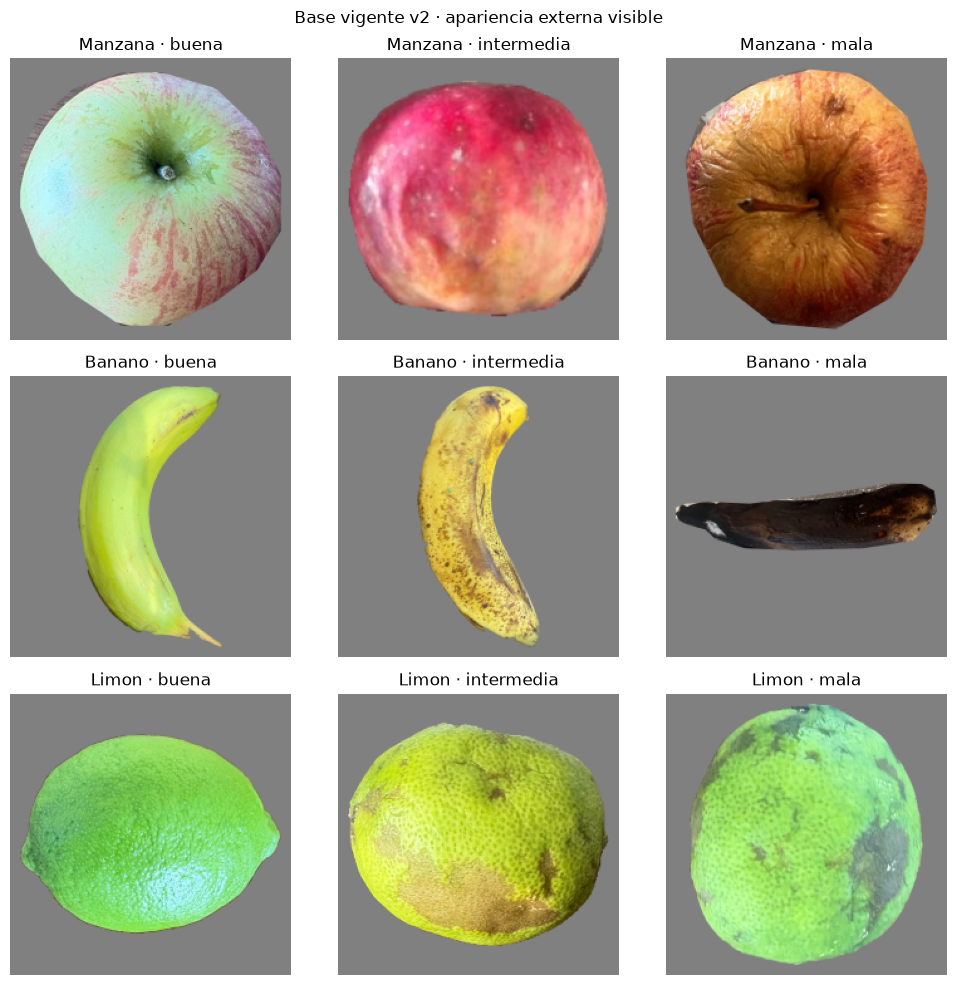

In [6]:
fig,ejes=plt.subplots(3,3,figsize=(10,10))
for i,fruta in enumerate(config['frutas']):
    for j,etiqueta in enumerate(config['calidades']):
        opciones=base.loc[base.fruta.eq(fruta)&base.calidad_revisada.eq(etiqueta)].sort_values(['fuente','codigo_revision'])
        eje=ejes[i,j];eje.axis('off');eje.set_title(f'{fruta.capitalize()} · {etiqueta}')
        if opciones.empty:eje.text(.5,.5,'Sin ejemplo confirmado',ha='center',va='center')
        else:
            with Image.open(opciones.iloc[0].ruta_cnn) as im:eje.imshow(im)
fig.suptitle('Base vigente v2 · apariencia externa visible')
fig.tight_layout();guardar_figura(fig,SALIDAS/'ejemplos_base_v2.jpg',dpi=110)
plt.show()

## 6. Comprobación del ajuste de SVM y Random Forest

Se usa todo el lote de desarrollo para verificar que ambos estimadores pueden
ajustarse. Las nueve combinaciones de fruta y calidad están presentes, con un
desequilibrio importante entre clases y pocas campañas. El mayor número de vistas
no se interpreta como un mayor número de frutos independientes.

Este ajuste no es una comparación de desempeño ni una selección de parámetros.
No se presentan métricas de generalización ni se guarda un modelo final. La
estandarización de SVM permanece dentro del Pipeline.


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

columnas=estado['caracteristicas'];X=base[columnas].astype(float);y=base.calidad_revisada
assert np.isfinite(X.to_numpy()).all()
assert not set(['fruta','fuente','id_ejemplar','grupo_particion','calidad_revisada'])&set(X.columns)
modelos={
    'SVM':Pipeline([('escalar',StandardScaler()),('modelo',SVC(C=1.,kernel='rbf',gamma='scale',class_weight='balanced'))]),
    'Random Forest':RandomForestClassifier(n_estimators=100,min_samples_leaf=2,class_weight='balanced',random_state=42,n_jobs=1),
}
filas=[]
for nombre,modelo in modelos.items():
    modelo.fit(X,y)
    assert set(modelo.classes_)==set(y)
    filas.append({'modelo':nombre,'ejemplares_desarrollo':len(X),'caracteristicas':len(columnas),
                  'clases':len(modelo.classes_),'ajuste_completado':True,'evaluacion_independiente':False})
comprobacion=pd.DataFrame(filas);display(comprobacion)
guardar_tabla(comprobacion,SALIDAS/'comprobacion_ajuste.csv')
guardar_bytes_si_cambio(SALIDAS/'estado_ajuste.json',json.dumps({'sha_base':estado['sha_base'],
    'alcance':'Comprobación técnica con el lote de desarrollo; sin métricas de generalización.',
    'evaluacion_independiente':False},ensure_ascii=False,indent=2).encode('utf-8'))

,modelo,ejemplares_desarrollo,caracteristicas,clases,ajuste_completado,evaluacion_independiente
0,SVM,291,43,3,True,False
1,Random Forest,291,43,3,True,False


## 7. Qué falta para comparar modelos

La revisión del lote y la resolución operativa de los cinco casos están completadas.
El cuaderno 05 añade identidades propuestas a las fotos propias de la base y refina
sus grupos seguros: se mantienen juntas las alternativas inciertas. Las fuentes
públicas conservan sus campañas. La base conserva 291 entradas y 43 características.

Siguen pendientes algunas correspondencias físicas, especialmente en limones, y
otras capturas para reservar una prueba independiente. Las 318 fotos utilizadas
para ajustar el procesamiento permanecen registradas como desarrollo. No se fuerza
una división aleatoria entre vistas relacionadas para obtener una métrica.

El plan agrupado exige cobertura y al menos cinco grupos por combinación como
mínimo operativo, sin garantizar suficiencia estadística. El conjunto actual no lo
cumple. Cuando haya datos adecuados, seleccionar parámetros con validación agrupada
y comparar macro-F1, balanced accuracy y matrices de confusión por fruta. El tamaño
continúa siendo relativo a píxeles, sin escala física calibrada.
